In [12]:
import pandas as pd

In [13]:
data=pd.read_csv('diabetes_prediction_dataset.csv')

In [14]:
data

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [15]:
data['gender'].value_counts()

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

In [16]:
data=data[data['gender']!='Other']

In [17]:
X=data.drop(columns=['diabetes'])
y=data['diabetes'].map({0:'no',1:'yes'})

In [18]:
standard_scaler_col_names=['age','bmi','HbA1c_level','blood_glucose_level']
ordinal_encoder_col_names=['gender']
one_hot_encoder_col_names=['smoking_history']

In [19]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [20]:
from sklearn.preprocessing import StandardScaler,OrdinalEncoder,OneHotEncoder
from sklearn.compose import ColumnTransformer

column_transformer=ColumnTransformer(
    transformers=[
        ('a',StandardScaler(),standard_scaler_col_names),
        ('b',OrdinalEncoder(),ordinal_encoder_col_names),
        ('c',OneHotEncoder(drop='first',sparse_output=False),one_hot_encoder_col_names)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

train_indexes=X_train.index
test_indexes=X_test.index

X_train=column_transformer.fit_transform(X_train)
X_test=column_transformer.transform(X_test)

feature_names=column_transformer.get_feature_names_out()
X_train=pd.DataFrame(X_train,columns=feature_names,index=train_indexes)
X_test=pd.DataFrame(X_test,columns=feature_names,index=test_indexes)

display(X_train)

,age,bmi,HbA1c_level,blood_glucose_level,gender,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current,hypertension,heart_disease
47095,-0.973876,0.915763,-1.894769,-0.294815,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
97571,1.558267,0.548905,0.627742,-0.196511,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
16749,-0.662911,1.774273,0.627742,-0.196511,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12730,-0.307523,-0.008901,-1.894769,-0.294815,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
95158,-0.751758,0.643626,0.254036,-1.179546,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
19939,-0.351946,-0.001383,0.627742,-0.933787,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
60656,1.691538,-1.262835,-0.493374,-1.425304,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
95475,-1.506959,-0.950103,0.534316,0.491613,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3489,-0.529641,0.670690,0.534316,1.523800,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import balanced_accuracy_score

decision_tree_classifier=DecisionTreeClassifier(criterion='gini',class_weight='balanced',max_depth=3,random_state=42)
decision_tree_classifier.fit(X_train,y_train)
y_pred_cat=decision_tree_classifier.predict(X_test)
print('Decision Tree Classification Balanced Accuracy:',balanced_accuracy_score(y_test,y_pred_cat))

Decision Tree Classification Balanced Accuracy: 0.8364705882352941


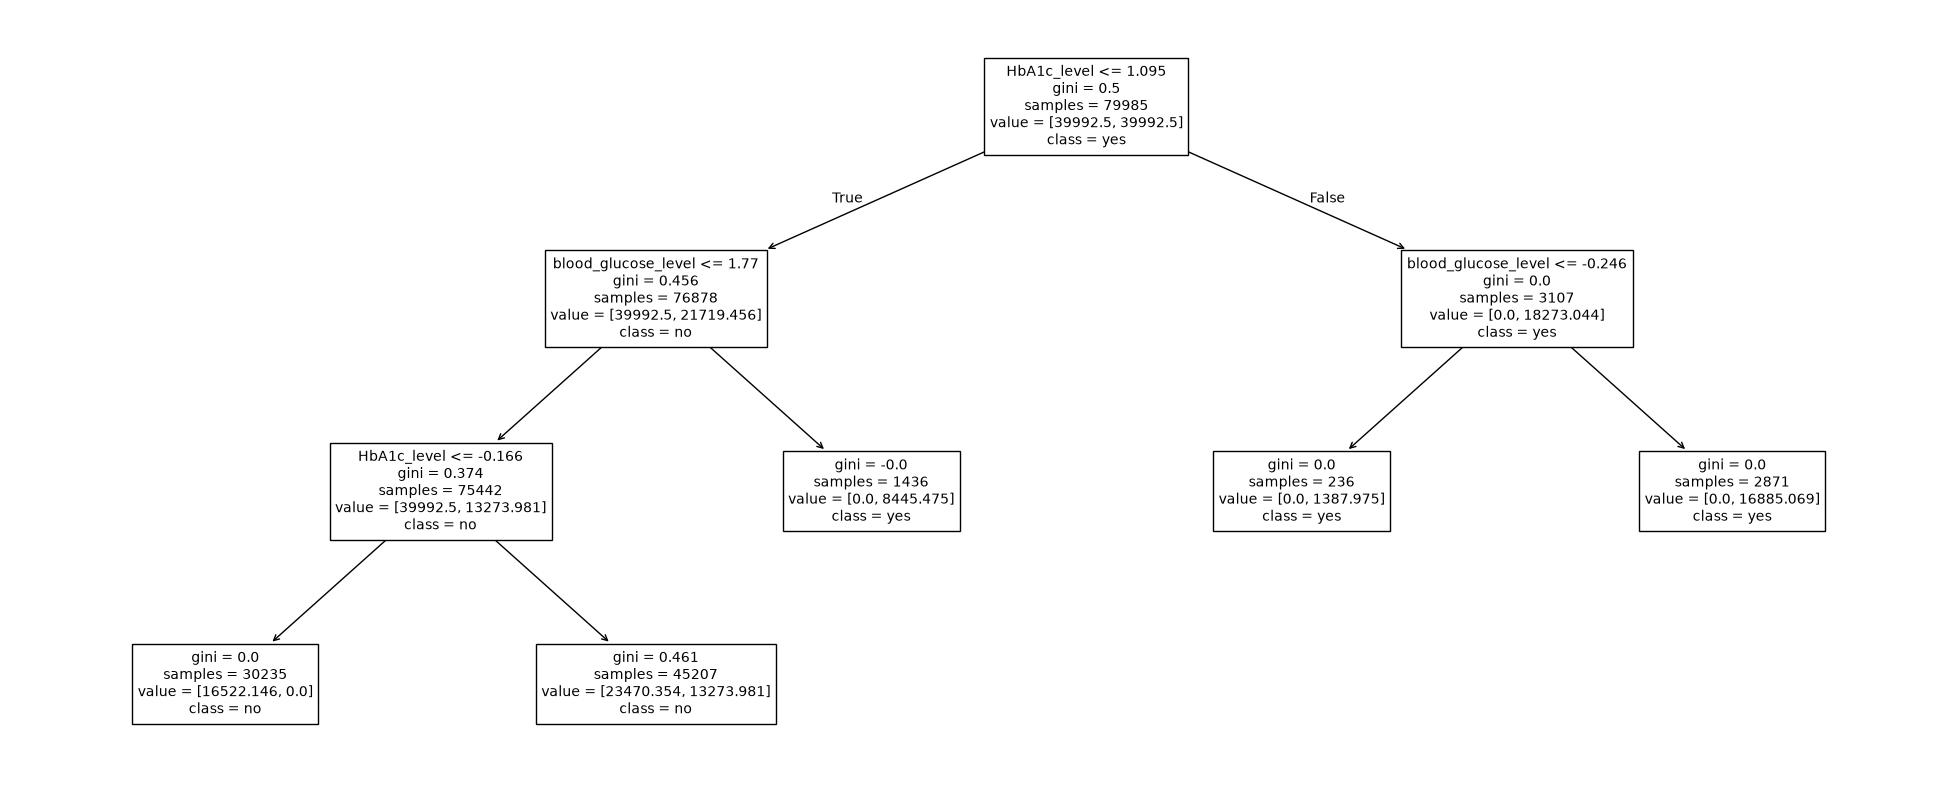

In [22]:
plt.figure(figsize=(25,10))
plot_tree(decision_tree_classifier,feature_names=feature_names,class_names=decision_tree_classifier.classes_,fontsize=10)
plt.show()